# Brain MERFISH: region-stratified proximity-associated DE across cleaning methods

Adaptation of `whole_mouse_brain_MERFISH_atlas_scripts_2023/scripts/ligand_receptor_analysis/contact_enriched_gene_exp.ipynb` and the upstream `cell_cell_contacts/{get_cells_by_regions,randomize_and_count_cell_cell_contacts_30um,get_significant_contacts_30um}.ipynb` notebooks.

**Methods:** Raw, ResolVI, SPLIT, Syndri (last). Ovrlpy and CellAdmix require transcript coordinates and have no corrected matrices for this dataset. These are three sagittal sections of **one animal**, Zhuang-ABCA-4; they are not three biological replicates.

## Preserved source design
- Subclass confidence >0.8; CCF major regions. Keep regional non-neuronal subclasses with >50 cells, astrocytes with regional enrichment >1, and neurons with enrichment >2 (>6 in Pons/Medulla and HY/MB subdivisions).
- Select contact-enriched subclass pairs using 30 µm contacts and 1,000 spatial randomizations: independently move each cell uniformly within a 100 µm disk, within its section/region's cell set. Normal-tail P values, BH over unordered pairs per region, adjusted P<0.05 and >50 observed contacts.
- For each direction of each selected pair: compare query cells at **0<distance<30 µm** from the closest reference-subclass cell with query cells at **distance>30 µm**. Same-subclass pairs use the second nearest cell, excluding self. Distances never cross slices. Pool cells across available slices within each region for the primary test.
- One-sided **Welch t-test** (`alternative='greater'`); BH adjustment across all tested gene × directed-pair comparisons **per region and method**. Report enrichment at **fold change>2 and adjusted P<0.01**.

## Explicit adaptations and limits
- CCF assignments are from the supplied `ccf_coordinates.csv`, joined by full string cell IDs. Region names come from the matching Allen CCF-2020 lookup; physical distances use measured x/y (mm→µm), not warped CCF distances. Unassigned regions are excluded. HY/MB splits use the source's CCF-x thresholds when present.
- Regional enrichment is recalculated from this three-section subset, not the full atlas. The original custom region-map JSON and contact-count helper are unavailable; region mapping uses Allen divisions/categories, and contact counts are **unordered distinct cell pairs** (no self edges).
- Test the **measured panel**, not the unavailable subclass-specific imputed HVGs. Normalize each matrix to 10,000 per cell, **without log transformation**, so arithmetic mean ratios remain interpretable. Preserve fractional corrected values. Genes must be detected in ≥5 raw query cells across the contact/control cohort; the same gene set is used across methods.
- Raw QC ≥10 counts/≥5 genes; identical cells across all methods, excluding missing/unscored cells and any cells with zero corrected library size. Add a minimum of 30 contact and 30 control cells. Save exclusion reasons and cell identities.
- Syndri uses class-specific probability scaling, target removal 0.3, power 2, minimum admixture probability 0.5, matching the brain metrics settings.
- Welch significance on model-estimated expression does not propagate ResolVI uncertainty. Neither loss nor retention of a proximity-associated signal alone proves contamination removal. Anatomical gradients and subtype composition can also produce proximity DE.

Outputs include region maps, contact selection, near/far counts, full DE tables, method comparisons and per-slice effect sizes for checking consistency. Existing outputs are never overwritten. Kernel: Python in `rctd`.

Data provenance: [Allen Zhuang MERFISH tutorial](https://alleninstitute.github.io/abc_atlas_access/notebooks/zhuang_merfish_tutorial.html#ccf-registration-and-parcellation-annotation), Allen CCF metadata release 20230630 (from atlas manifest 20230830).

In [1]:
from pathlib import Path
from types import SimpleNamespace
from concurrent.futures import ThreadPoolExecutor
import sys,json,hashlib,re,gc,warnings
import numpy as np
import pandas as pd
import anndata as ad
import h5py
from scipy import sparse,stats
from scipy.spatial import cKDTree
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT=Path('/home/jwinchel/Syndri')
ROOT=Path('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish')
ATLAS=Path('/home/jwinchel/whole_mouse_brain_MERFISH_atlas_scripts_2023')
CCF_FILE=ROOT/'raw/spatial/ccf_coordinates.csv'
LOOKUP_FILE=PROJECT/'figures/resources/brain_merfish_atlas/parcellation_to_parcellation_term_membership_acronym.csv'
sys.path.insert(0,str(PROJECT/'eval'))
from metrics_eval import cleaned_counts_for_removed_fraction_maybe_grouped
METHODS=['Raw','ResolVI','SPLIT','Syndri']
COLORS={'Raw':'#5cafe0','ResolVI':'#9046ad','SPLIT':'#20b1a9','Syndri':'#4056a1'}
CONTACT_RADIUS=30.;JITTER_RADIUS=100.;N_PERMUTATIONS=1000;THREADS=4;SEED=123
MIN_COUNTS=10;MIN_GENES=5;MIN_GROUP_SIZE=30;MIN_GENE_CELLS=5
CONFIDENCE=0.8;MIN_CONTACT_EDGES=50;CONTACT_Q=0.05;DE_Q=0.01;MIN_FOLD_CHANGE=2.
NORMALIZE_TARGET=10_000.;COORDINATE_TO_UM=1000.
SYNDRI_TARGET=.3
CLEAN_ARGS=SimpleNamespace(cell_type_specific_removal=True,cleaning_mode='probability_scale',
    probability_transform='power',probability_power=2.,clean_prob_threshold=.5)
REGIONS=None  # None = every mapped source region; e.g. ['Isocortex','Hippocampus']
SLICE_SUBSET=None  # None = all three sections.
PLOT_TOP_N=30
plt.rcParams.update({'pdf.fonttype':42,'svg.fonttype':'none','font.size':9})


In [2]:
def file_signature(path):
    path = Path(path)
    st = path.stat()
    return {'path': str(path.resolve()), 'size': st.st_size, 'mtime_ns': st.st_mtime_ns}

def read_metadata(path):
    with h5py.File(path, 'r') as f:
        return ad.io.read_elem(f['obs']), ad.io.read_elem(f['var'])

def read_matrix(path, layer=None):
    # Read one matrix only: loading an entire h5ad also loads large probability layers.
    with h5py.File(path, 'r') as f:
        key = 'X' if layer is None else f'layers/{layer}'
        if key not in f:
            raise KeyError(f'{path}: missing {key}')
        return sparse.csr_matrix(ad.io.read_elem(f[key]))

def resolved_gene_symbols(var):
    """Resolve annotation placeholders using symbol-valued feature IDs.

    CosMx stores DDX58/C9orf16/MTRNR2L1 in the index with gene_symbol='N/A'.
    Never interpret an unmapped Ensembl ID as a gene symbol.
    """
    key = next((k for k in ['feature_name', 'gene_symbol', 'name'] if k in var.columns), None)
    ids = pd.Series(var.index.astype(str), index=var.index, dtype='string').str.strip()
    symbols = var[key].astype('string').str.strip() if key else ids.copy()
    placeholders = {'', 'n/a', 'na', 'nan', 'none', 'null', '<na>'}
    missing = symbols.isna() | symbols.str.lower().isin(placeholders)
    valid_id = (ids.notna() & ~ids.str.lower().isin(placeholders)
                & ~ids.str.match(r'^ENS[A-Z]*G[0-9]+(?:\.[0-9]+)?$', na=False))
    symbols = symbols.mask(missing).fillna(ids.where(valid_id))
    return symbols

In [3]:
paths=sorted((ROOT/'results/final').glob('*.h5ad'))
if SLICE_SUBSET is not None:
    assert set(SLICE_SUBSET)<={p.stem for p in paths}
    paths=[p for p in paths if p.stem in SLICE_SUBSET]
assert paths
manifest=[]
for p in paths:
    for method in METHODS:
        src=ROOT/'results/competitors/resolvi'/p.name if method=='ResolVI' else p
        manifest.append(dict(slice=p.stem,method=method,path=str(src),available=src.is_file()))
manifest=pd.DataFrame(manifest);display(manifest)
if not manifest.available.all():raise FileNotFoundError('Selected methods must be available on every selected slice; inspect manifest.')
settings=dict(version=1,methods=METHODS,regions=REGIONS,contact_radius=CONTACT_RADIUS,jitter_radius=JITTER_RADIUS,
    n_permutations=N_PERMUTATIONS,seed=SEED,raw_qc=[MIN_COUNTS,MIN_GENES],min_group=MIN_GROUP_SIZE,
    min_gene_cells=MIN_GENE_CELLS,confidence=CONFIDENCE,min_contact_edges=MIN_CONTACT_EDGES,contact_q=CONTACT_Q,
    de_q=DE_Q,min_fc=MIN_FOLD_CHANGE,normalization=NORMALIZE_TARGET,coordinate_to_um=COORDINATE_TO_UM,
    syndri_target=SYNDRI_TARGET,cleaning=vars(CLEAN_ARGS),
    files=[file_signature(p) for p in sorted(set(manifest.path))],
    ccf=file_signature(CCF_FILE),lookup_sha256=hashlib.sha256(LOOKUP_FILE.read_bytes()).hexdigest(),
    evaluator_sha256=hashlib.sha256((PROJECT/'eval/metrics_eval.py').read_bytes()).hexdigest())
RUN_DIR=PROJECT/'figures/outputs/brain_merfish_proximity_de'/hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()[:16]
RUN_DIR.mkdir(parents=True,exist_ok=True)
if not (RUN_DIR/'settings.json').exists():
    with (RUN_DIR/'settings.json').open('x') as out:json.dump(settings,out,indent=2)
print('Results:',RUN_DIR)

ccf=pd.read_csv(CCF_FILE,dtype={'cell_label':str}).set_index('cell_label')
lookup=pd.read_csv(LOOKUP_FILE).set_index('parcellation_index')
assert ccf.index.is_unique and lookup.index.is_unique
annotation=ccf.join(lookup,on='parcellation_index',rsuffix='_lookup')
region_map={'CB':'Cerebellum','CTXsp':'Cortical_subplate','HPF':'Hippocampus','Isocortex':'Isocortex',
            'MY':'Medulla','OLF':'Olfactory','PAL':'Pallidum','P':'Pons','STR':'Striatum','TH':'Thalamus'}
annotation['region']=annotation.division.map(region_map)
annotation.loc[annotation.category.eq('fiber tracts'),'region']='Fiber_tracts'
annotation.loc[annotation.category.eq('VS'),'region']='Ventricular_systems'
for division,threshold,anterior,posterior in [('HY',6.4814041375,'anterior_HY','posterior_HY'),('MB',9.191019475,'anterior_MB','posterior_MB')]:
    mask=annotation.division.eq(division)
    annotation.loc[mask,'region']=np.where(annotation.loc[mask,'x']<threshold,anterior,posterior)


,slice,method,path,available
0,st_integrated_slice-Zhuang-ABCA-4.001,Raw,/work/magroup/skrieger/Syndri/data/datasets/br...,True
1,st_integrated_slice-Zhuang-ABCA-4.001,ResolVI,/work/magroup/skrieger/Syndri/data/datasets/br...,True
2,st_integrated_slice-Zhuang-ABCA-4.001,SPLIT,/work/magroup/skrieger/Syndri/data/datasets/br...,True
3,st_integrated_slice-Zhuang-ABCA-4.001,Syndri,/work/magroup/skrieger/Syndri/data/datasets/br...,True
4,st_integrated_slice-Zhuang-ABCA-4.002,Raw,/work/magroup/skrieger/Syndri/data/datasets/br...,True
5,st_integrated_slice-Zhuang-ABCA-4.002,ResolVI,/work/magroup/skrieger/Syndri/data/datasets/br...,True
6,st_integrated_slice-Zhuang-ABCA-4.002,SPLIT,/work/magroup/skrieger/Syndri/data/datasets/br...,True
7,st_integrated_slice-Zhuang-ABCA-4.002,Syndri,/work/magroup/skrieger/Syndri/data/datasets/br...,True
8,st_integrated_slice-Zhuang-ABCA-4.003,Raw,/work/magroup/skrieger/Syndri/data/datasets/br...,True
9,st_integrated_slice-Zhuang-ABCA-4.003,ResolVI,/work/magroup/skrieger/Syndri/data/datasets/br...,True


Results: /home/jwinchel/Syndri/figures/outputs/brain_merfish_proximity_de/38a61c5ddef560c7


## 1. Fixed cells and measured expression
Stage one section at a time. Cache only the aligned analysis cells/matrices in the new output directory. Missing metadata is never filled by assigning a cell type or region. Original full IDs remain strings.

In [4]:
def prepare_slice(path):
    dest=RUN_DIR/'prepared'/path.stem
    if (dest/'complete.json').exists():return json.loads((dest/'complete.json').read_text())
    dest.mkdir(parents=True,exist_ok=True)
    # New attempt avoids overwriting partial files if a previous execution was interrupted.
    k=1
    while (dest/f'attempt_{k}').exists():k+=1
    work=dest/f'attempt_{k}';work.mkdir()
    obs,var=read_metadata(path)
    assert obs.index.is_unique and var.index.is_unique
    symbols=resolved_gene_symbols(var)
    if symbols.isna().any() or symbols.duplicated().any():raise ValueError('Unresolved gene symbols')
    raw=read_matrix(path)
    base=(obs.subclass.notna() & obs['class'].notna() & obs.subclass_confidence_score.gt(CONFIDENCE)
          & np.isfinite(obs[['x','y']]).all(axis=1))
    base &= (np.asarray(raw.sum(1)).ravel()>=MIN_COUNTS)&(np.asarray((raw>0).sum(1)).ravel()>=MIN_GENES)
    obs=obs.copy();obs['region']=annotation.region.reindex(obs.index)
    n_pre_region=int(base.sum())
    base &= obs.region.notna()
    if REGIONS is not None:base &= obs.region.isin(REGIONS)
    idx=np.flatnonzero(base.to_numpy());names=obs.index[idx]
    matrices={};keep=np.ones(len(idx),bool)
    for method in METHODS:
        if method=='Raw':X=raw[idx].astype(float)
        elif method=='SPLIT':X=read_matrix(path,'split_purified_counts_X')[idx].astype(float)
        elif method=='Syndri':
            probs=read_matrix(path,'syndri_admix_probs_X')
            X=cleaned_counts_for_removed_fraction_maybe_grouped(raw,probs,SYNDRI_TARGET,CLEAN_ARGS,labels=obs['class'])[0][idx].astype(float)
            del probs
        elif method=='ResolVI':
            src=ROOT/'results/competitors/resolvi'/path.name
            ro,rv=read_metadata(src);ri=ro.index.get_indexer(names);gi=rv.index.get_indexer(var.index)
            if (ri<0).any() or (gi<0).any():raise ValueError('ResolVI cells/genes do not align')
            X=read_matrix(src,'resolvi_corrected_counts')[ri][:,gi].astype(float)
            if 'resolvi_scored' in ro:keep &= ro.iloc[ri].resolvi_scored.to_numpy(dtype=bool)
        else:raise ValueError(method)
        if not np.isfinite(X.data).all() or (X.data<0).any():raise ValueError(f'Invalid {method} expression')
        keep &= np.asarray(X.sum(1)).ravel()>0
        matrices[method]=X
    outobs=obs.iloc[idx[keep]][['x','y','region','subclass','class','donor_label']].copy()
    outobs['slice']=path.stem
    outobs['subclass']=outobs.subclass.astype(str).str.replace(r'^\d+\s+','',regex=True)
    outobs['x_um']=outobs.x*COORDINATE_TO_UM;outobs['y_um']=outobs.y*COORDINATE_TO_UM
    outobs.to_csv(work/'cells.csv',index_label='cell_id',mode='x')
    pd.DataFrame({'feature_id':var.index,'gene':symbols.to_numpy()}).to_csv(work/'genes.csv',index=False,mode='x')
    for method,X in matrices.items():
        X=X[keep].tocsr();tot=np.asarray(X.sum(1)).ravel()
        if method=='Raw':sparse.save_npz(work/'raw_detection.npz',(X>0).astype(np.int8))
        X=(sparse.diags(NORMALIZE_TARGET/tot)@X).tocsr()
        sparse.save_npz(work/f'{method}.npz',X)
    report=dict(path=str(work),slice=path.stem,n_total=len(obs),n_raw_qc_metadata=n_pre_region,
                n_region_eligible=len(idx),n_common=len(outobs),n_excluded_total=len(obs)-len(outobs))
    with (dest/'complete.json').open('x') as out:json.dump(report,out,indent=2)
    print(report,flush=True);return report

prepared=[prepare_slice(p) for p in paths]
display(pd.DataFrame(prepared).drop(columns='path'))
obs_all=pd.concat([pd.read_csv(Path(p['path'])/'cells.csv',dtype={'cell_id':str}).set_index('cell_id') for p in prepared])
assert obs_all.index.is_unique
# Regional enrichment relative to the sampled subset, following the source's cell-type rules.
counts=pd.crosstab(obs_all.subclass,obs_all.region)
expected=np.outer(counts.sum(1),counts.sum(0))/counts.values.sum()
enrichment=counts/expected
selection=[]
for region in counts.columns:
    for ct in counts.index:
        n=int(counts.loc[ct,region]);ratio=float(enrichment.loc[ct,region])
        if ct.endswith('NN') and not ct.startswith('Astro'):selected=n>50
        elif ct.startswith('Astro'):selected=ratio>1 and n>0
        else:selected=ratio>(6 if region in ['Pons','Medulla','anterior_HY','posterior_HY','anterior_MB','posterior_MB'] else 2) and n>0
        selection.append(dict(region=region,subclass=ct,n_cells=n,enrichment=ratio,selected=selected))
selection=pd.DataFrame(selection)
if not (RUN_DIR/'regional_subclass_selection.csv').exists():selection.to_csv(RUN_DIR/'regional_subclass_selection.csv',index=False,mode='x')
display(selection[selection.selected].groupby('region').agg(subclasses=('subclass','size'),cells=('n_cells','sum')))


{'path': '/home/jwinchel/Syndri/figures/outputs/brain_merfish_proximity_de/38a61c5ddef560c7/prepared/st_integrated_slice-Zhuang-ABCA-4.001/attempt_1', 'slice': 'st_integrated_slice-Zhuang-ABCA-4.001', 'n_total': 53701, 'n_raw_qc_metadata': 32483, 'n_region_eligible': 31352, 'n_common': 31352, 'n_excluded_total': 22349}
{'path': '/home/jwinchel/Syndri/figures/outputs/brain_merfish_proximity_de/38a61c5ddef560c7/prepared/st_integrated_slice-Zhuang-ABCA-4.002/attempt_1', 'slice': 'st_integrated_slice-Zhuang-ABCA-4.002', 'n_total': 66473, 'n_raw_qc_metadata': 50052, 'n_region_eligible': 48746, 'n_common': 48746, 'n_excluded_total': 17727}
{'path': '/home/jwinchel/Syndri/figures/outputs/brain_merfish_proximity_de/38a61c5ddef560c7/prepared/st_integrated_slice-Zhuang-ABCA-4.003/attempt_1', 'slice': 'st_integrated_slice-Zhuang-ABCA-4.003', 'n_total': 95104, 'n_raw_qc_metadata': 79997, 'n_region_eligible': 78420, 'n_common': 78420, 'n_excluded_total': 16684}


,slice,n_total,n_raw_qc_metadata,n_region_eligible,n_common,n_excluded_total
0,st_integrated_slice-Zhuang-ABCA-4.001,53701,32483,31352,31352,22349
1,st_integrated_slice-Zhuang-ABCA-4.002,66473,50052,48746,48746,17727
2,st_integrated_slice-Zhuang-ABCA-4.003,95104,79997,78420,78420,16684


,subclasses,cells
region,,
Cerebellum,19,46785
Cortical_subplate,30,5053
Fiber_tracts,26,7995
Hippocampus,36,22509
Isocortex,25,42056
Medulla,11,800
Olfactory,23,8268
Pallidum,17,614
Pons,1,1


## 2. Contact-enriched pairs: local spatial null
The same geometry and selected subclass pairs are used for every expression method. Coordinates are jittered in a 100 µm disk, exactly as in the source null; jitter is not clipped back to region boundaries. Distinct unordered cell pairs are counted at ≤30 µm (the DE group definition below uses the source's strict inequalities).

In [5]:
def contact_counts(xy,codes,n_types):
    codes=np.asarray(codes,dtype=np.int64)  # categorical int8 codes overflow when flattened
    edges=cKDTree(xy).query_pairs(CONTACT_RADIUS,output_type='ndarray')
    if not len(edges):return np.zeros(n_types*n_types,dtype=np.int64)
    a=codes[edges[:,0]];b=codes[edges[:,1]]
    return np.bincount(np.minimum(a,b)*n_types+np.maximum(a,b),minlength=n_types*n_types)


def select_contacts(region,region_obs):
    out=RUN_DIR/'contacts';out.mkdir(exist_ok=True)
    file=out/f'{region}.csv'
    if file.exists():return pd.read_csv(file)
    types=np.array(sorted(region_obs.subclass.unique()));nt=len(types)
    groups=[]
    for _,s in region_obs.groupby('slice',sort=True):
        groups.append((s[['x_um','y_um']].to_numpy(),pd.Categorical(s.subclass,categories=types).codes))
    observed=sum((contact_counts(xy,code,nt) for xy,code in groups),np.zeros(nt*nt,dtype=np.int64))
    region_seed=int(hashlib.sha256(region.encode()).hexdigest()[:8],16)
    def one_permutation(i):
        rng=np.random.default_rng(np.random.SeedSequence([SEED,region_seed,i]))
        total=np.zeros(nt*nt,dtype=np.int64)
        for xy,codes in groups:
            radius=JITTER_RADIUS*np.sqrt(rng.random(len(xy)));angle=2*np.pi*rng.random(len(xy))
            shuffled=xy+np.column_stack([radius*np.sin(angle),radius*np.cos(angle)])
            total+=contact_counts(shuffled,codes,nt)
        return total
    sums=np.zeros(nt*nt);squares=np.zeros(nt*nt)
    with ThreadPoolExecutor(max_workers=THREADS) as pool:
        for i,values in enumerate(pool.map(one_permutation,range(N_PERMUTATIONS)),1):
            sums+=values;squares+=values.astype(float)**2
            if i%100==0:print(region,'permutations',i,'/',N_PERMUTATIONS,flush=True)
    mean=sums/N_PERMUTATIONS
    sd=np.maximum(np.sqrt(np.maximum(squares/N_PERMUTATIONS-mean**2,0)),np.sqrt(1/N_PERMUTATIONS))
    a,b=np.triu_indices(nt);indices=a*nt+b
    z=(observed[indices]-mean[indices])/sd[indices];p=stats.norm.sf(z)
    q=multipletests(p,method='fdr_bh')[1]
    result=pd.DataFrame({'region':region,'query':types[a],'reference':types[b],'contact_count':observed[indices],
                        'null_mean':mean[indices],'null_sd':sd[indices],'z':z,'p':p,'q':q})
    result['selected']=(result.q<CONTACT_Q)&(result.contact_count>MIN_CONTACT_EDGES)
    result.to_csv(file,index=False,mode='x');return result

contact_frames=[];region_obs={}
for region in sorted(selection.region.unique()):
    types=selection.loc[selection.region.eq(region)&selection.selected,'subclass']
    o=obs_all[obs_all.region.eq(region)&obs_all.subclass.isin(types)]
    if len(o)<2:continue
    region_obs[region]=o
    contact_frames.append(select_contacts(region,o))
contacts=pd.concat(contact_frames,ignore_index=True) if contact_frames else pd.DataFrame(columns=['region','selected'])
display(contacts.groupby('region').selected.agg(['sum','size']).rename(columns={'sum':'selected_pairs','size':'tested_pairs'}))


Cerebellum permutations 100 / 1000
Cerebellum permutations 200 / 1000
Cerebellum permutations 300 / 1000
Cerebellum permutations 400 / 1000
Cerebellum permutations 500 / 1000
Cerebellum permutations 600 / 1000
Cerebellum permutations 700 / 1000
Cerebellum permutations 800 / 1000
Cerebellum permutations 900 / 1000
Cerebellum permutations 1000 / 1000
Cortical_subplate permutations 100 / 1000
Cortical_subplate permutations 200 / 1000
Cortical_subplate permutations 300 / 1000
Cortical_subplate permutations 400 / 1000
Cortical_subplate permutations 500 / 1000
Cortical_subplate permutations 600 / 1000
Cortical_subplate permutations 700 / 1000
Cortical_subplate permutations 800 / 1000
Cortical_subplate permutations 900 / 1000
Cortical_subplate permutations 1000 / 1000
Fiber_tracts permutations 100 / 1000
Fiber_tracts permutations 200 / 1000
Fiber_tracts permutations 300 / 1000
Fiber_tracts permutations 400 / 1000
Fiber_tracts permutations 500 / 1000
Fiber_tracts permutations 600 / 1000
Fiber_

,selected_pairs,tested_pairs
region,,
Cerebellum,35,190
Cortical_subplate,10,465
Fiber_tracts,16,351
Hippocampus,30,666
Isocortex,22,325
Medulla,3,66
Olfactory,12,276
Pallidum,1,153
Striatum,11,496


## 3. Directed proximity groups and Welch DE
Contact and control cells are pooled across sections **within a region**. The same cell IDs, genes, and hypotheses are tested for each method. Per-section effect sizes are exported separately to expose inconsistent effects; those sections share one donor. Zero control means yield infinite fold change when contact expression is positive; no pseudocount is used for significance selection.

In [6]:
def distance_groups(o,query,reference):
    contact=[];control=[]
    for _,s in o.groupby('slice',sort=True):
        a=s[s.subclass.eq(query)];b=s[s.subclass.eq(reference)]
        if len(a)<2 or len(b)<2:continue
        dist=cKDTree(b[['x_um','y_um']].to_numpy()).query(a[['x_um','y_um']].to_numpy(),k=2 if query==reference else 1)[0]
        if query==reference:dist=dist[:,1]
        contact.extend(a.index[(dist>0)&(dist<CONTACT_RADIUS)])
        control.extend(a.index[dist>CONTACT_RADIUS])
    return pd.Index(contact),pd.Index(control)


def moments(X):
    return X.shape[0],np.asarray(X.sum(0)).ravel(),np.asarray(X.multiply(X).sum(0)).ravel()


def welch_from_moments(n1,s1,ss1,n0,s0,ss0):
    m1=s1/n1;m0=s0/n0
    v1=np.maximum((ss1-s1*s1/n1)/(n1-1),0);v0=np.maximum((ss0-s0*s0/n0)/(n0-1),0)
    with np.errstate(divide='ignore',invalid='ignore'):
        stat,p=stats.ttest_ind_from_stats(m1,np.sqrt(v1),n1,m0,np.sqrt(v0),n0,equal_var=False,alternative='greater')
        fc=np.divide(m1,m0);logfc=np.log2(fc)
    return m1,m0,fc,logfc,stat,p


def analyze_region(region):
    folder=RUN_DIR/'de'/region;folder.mkdir(parents=True,exist_ok=True)
    if (folder/'complete.json').exists():return
    attempt=1
    while (folder/f'attempt_{attempt}').exists():attempt+=1
    dest=folder/f'attempt_{attempt}';dest.mkdir()
    chosen=contacts[contacts.region.eq(region)&contacts.selected]
    pairs=[]
    for r in chosen.itertuples():
        pairs.append((r.query,r.reference))
        if r.query!=r.reference:pairs.append((r.reference,r.query))
    groups=[];status=[]
    for q,r in pairs:
        near,far=distance_groups(region_obs[region],q,r)
        ok=min(len(near),len(far))>=MIN_GROUP_SIZE
        status.append(dict(region=region,query=q,reference=r,n_contact=len(near),n_control=len(far),status='ok' if ok else 'insufficient contact/control cells'))
        if ok:groups.append((q,r,near,far))
    pd.DataFrame(status,columns=['region','query','reference','n_contact','n_control','status']).to_csv(dest/'status.csv',index=False,mode='x')
    # Store cell membership once for audit; distance groups are independent of cleaning method.
    memberships=[]
    for q,r,a,b in groups:
        memberships.extend([pd.DataFrame({'query':q,'reference':r,'cell_id':ids,'group':label}) for ids,label in [(a,'contact'),(b,'control')]])
    (pd.concat(memberships,ignore_index=True) if memberships else pd.DataFrame(columns=['query','reference','cell_id','group'])).to_csv(dest/'memberships.csv.gz',index=False,mode='x')
    gene_table=pd.read_csv(Path(prepared[0]['path'])/'genes.csv');ng=len(gene_table)
    detection={i:np.zeros(ng) for i in range(len(groups))}
    accum={(m,i):[0,np.zeros(ng),np.zeros(ng),0,np.zeros(ng),np.zeros(ng)] for m in METHODS for i in range(len(groups))}
    slice_effects=[]
    for record in prepared:
        work=Path(record['path']);o=pd.read_csv(work/'cells.csv',dtype={'cell_id':str}).set_index('cell_id')
        gt=pd.read_csv(work/'genes.csv')
        if not gt.equals(gene_table):raise ValueError('Measured gene panels differ between sections')
        indices={}
        for i,(_,_,a,b) in enumerate(groups):
            ia=o.index.get_indexer(a);ib=o.index.get_indexer(b);indices[i]=(ia[ia>=0],ib[ib>=0])
        D=sparse.load_npz(work/'raw_detection.npz')
        for i,(ia,ib) in indices.items():detection[i]+=np.asarray(D[np.concatenate([ia,ib])].sum(0)).ravel()
        del D
        for method in METHODS:
            X=sparse.load_npz(work/f'{method}.npz')
            for i,(ia,ib) in indices.items():
                n1,s1,ss1=moments(X[ia]);n0,s0,ss0=moments(X[ib])
                values=[n1,s1,ss1,n0,s0,ss0]
                accum[(method,i)]=[a+b for a,b in zip(accum[(method,i)],values)]
                if n1>=MIN_GROUP_SIZE and n0>=MIN_GROUP_SIZE:
                    m1,m0,fc,lfc,_,_=welch_from_moments(*values)
                    q,r=groups[i][:2]
                    slice_effects.append(pd.DataFrame({'slice':record['slice'],'method':method,'query':q,'reference':r,
                        'gene':gene_table.gene,'contact_mean':m1,'control_mean':m0,'fold_change':fc,'log2fc':lfc,'n_contact':n1,'n_control':n0}))
            del X;gc.collect()
    frames=[]
    for method in METHODS:
        method_frames=[]
        for i,(q,r,a,b) in enumerate(groups):
            values=accum[(method,i)];m1,m0,fc,lfc,t,p=welch_from_moments(*values)
            keep=detection[i]>=MIN_GENE_CELLS
            # Undefined constant-gene tests receive p=1, preserving a common hypothesis universe.
            p=np.where(np.isfinite(p),p,1.)
            method_frames.append(pd.DataFrame({'region':region,'method':method,'query':q,'reference':r,
                'gene':gene_table.gene[keep].to_numpy(),'feature_id':gene_table.feature_id[keep].to_numpy(),
                'contact_mean':m1[keep],'control_mean':m0[keep],'fold_change':fc[keep],'log2fc':lfc[keep],
                't':t[keep],'p':p[keep],'n_contact':len(a),'n_control':len(b)}))
        if method_frames:
            d=pd.concat(method_frames,ignore_index=True)
            d['q']=multipletests(d.p,method='fdr_bh')[1]
            d['significant']=(d.q<DE_Q)&(d.fold_change>MIN_FOLD_CHANGE)
            frames.append(d)
    columns=['region','method','query','reference','gene','feature_id','contact_mean','control_mean','fold_change','log2fc','t','p','n_contact','n_control','q','significant']
    results=pd.concat(frames,ignore_index=True) if frames else pd.DataFrame(columns=columns)
    results.to_csv(dest/'de.csv.gz',index=False,mode='x')
    if slice_effects:pd.concat(slice_effects,ignore_index=True).to_csv(dest/'slice_effects.csv.gz',index=False,mode='x')
    with (folder/'complete.json').open('x') as out:json.dump({'path':str(dest),'pairs_tested':len(groups),'pairs_selected':len(pairs)},out,indent=2)
    print(region,'tested',len(groups),'directed pairs',flush=True)

for region in region_obs:analyze_region(region)
frames=[];statuses=[]
for region in region_obs:
    folder=Path(json.loads((RUN_DIR/'de'/region/'complete.json').read_text())['path'])
    frames.append(pd.read_csv(folder/'de.csv.gz'));statuses.append(pd.read_csv(folder/'status.csv'))
de=pd.concat(frames,ignore_index=True) if frames else pd.DataFrame()
status=pd.concat(statuses,ignore_index=True) if statuses else pd.DataFrame()
display(status.groupby(['region','status']).size().rename('pairs').to_frame() if len(status) else status)


Cerebellum tested 51 directed pairs
Cortical_subplate tested 13 directed pairs
Fiber_tracts tested 24 directed pairs
Hippocampus tested 35 directed pairs
Isocortex tested 35 directed pairs
Medulla tested 5 directed pairs
Olfactory tested 19 directed pairs
Pallidum tested 0 directed pairs
Striatum tested 15 directed pairs
Thalamus tested 0 directed pairs
Ventricular_systems tested 3 directed pairs


/tmp/ipykernel_3272971/2660418203.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  de=pd.concat(frames,ignore_index=True) if frames else pd.DataFrame()


pairs
region              status                                   
Cerebellum          insufficient contact/control cells      9
                    ok                                     51
Cortical_subplate   insufficient contact/control cells      1
                    ok                                     13
Fiber_tracts        insufficient contact/control cells      2
                    ok                                     24
Hippocampus         insufficient contact/control cells     10
                    ok                                     35
Isocortex           ok                                     35
Medulla             ok                                      5
Olfactory           insufficient contact/control cells      1
                    ok                                     19
Pallidum            insufficient contact/control cells      1
Striatum            insufficient contact/control cells      2
                    ok                                     15
Ventricular_systems insufficient contact/control cells      8
                    ok                                      3

## 4. Region maps and cross-method comparisons
The heatmap rows are directed subclass pairs and colors summarize the number of enriched genes. A zero means the pair was tested with no significant genes; missing pairs are gray. Selected gene examples are the top Raw-associated measured signals, chosen once and shown for every method. The source's Vip ↔ L2/3 IT CTX examples are reported if they pass contact selection and cell-count thresholds; their absence is not interpreted as a failed replication.

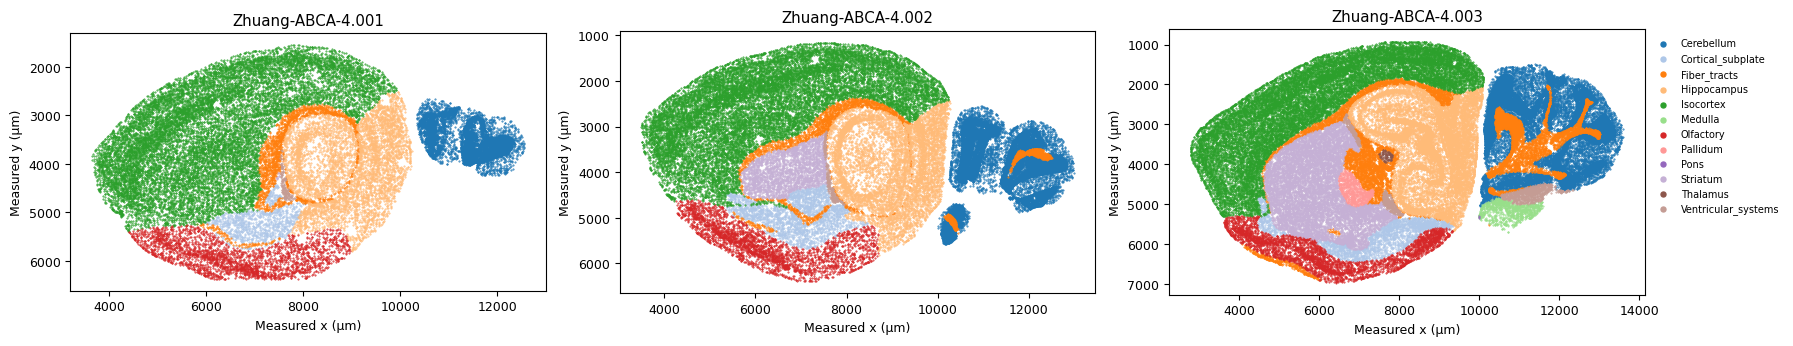

method,Raw,ResolVI,SPLIT,Syndri
region,,,,
Cerebellum,442,1026,363,327
Cortical_subplate,4,47,0,3
Fiber_tracts,82,309,41,22
Hippocampus,422,1131,410,262
Isocortex,211,1435,202,164
Medulla,1,0,1,1
Olfactory,40,614,40,27
Striatum,118,627,109,68
Ventricular_systems,0,0,0,0


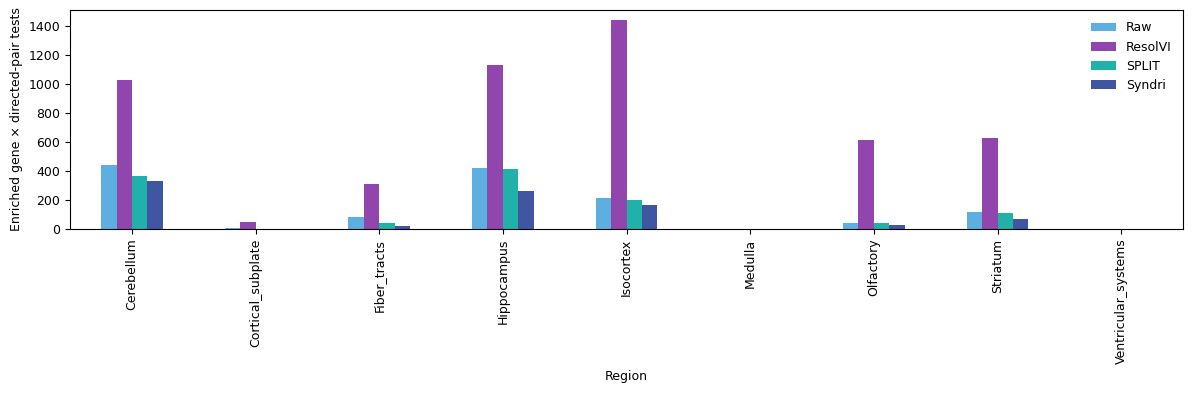

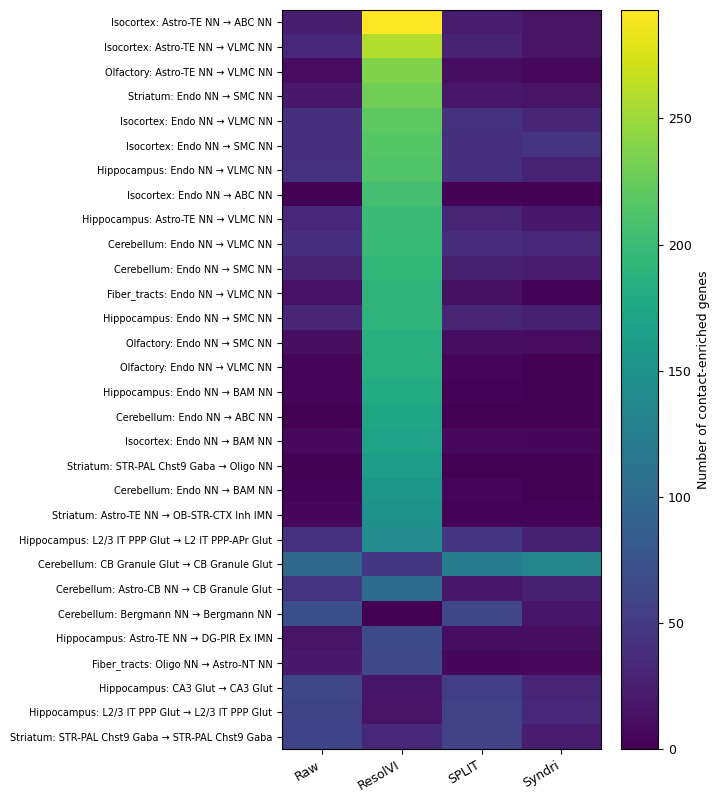

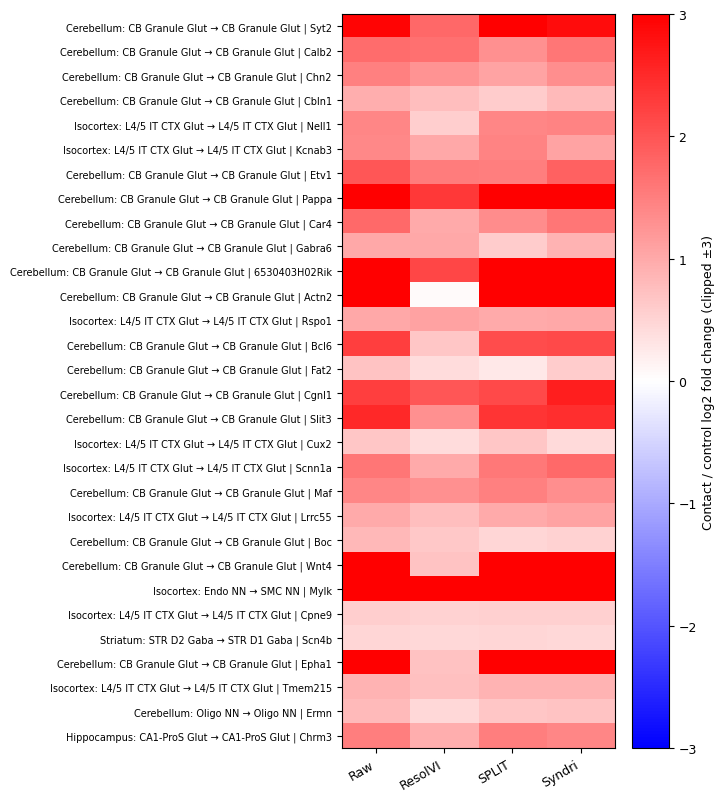

,method,shared_tests,raw_significant,method_significant,shared_significant,jaccard
0,ResolVI,179117,1320,5189,565,0.095054
1,SPLIT,179117,1320,1166,982,0.652926
2,Syndri,179117,1320,874,641,0.412750


Source example directions, measured genes only:


,region,method,query,reference,gene,feature_id,contact_mean,control_mean,fold_change,log2fc,t,p,n_contact,n_control,q,significant


Outputs: /home/jwinchel/Syndri/figures/outputs/brain_merfish_proximity_de/38a61c5ddef560c7


In [7]:
def save_new(fig,name):
    i=1
    while any((RUN_DIR/f'{name}_{i}.{ext}').exists() for ext in ['png','pdf']):i+=1
    for ext in ['png','pdf']:fig.savefig(RUN_DIR/f'{name}_{i}.{ext}',dpi=200,bbox_inches='tight')

fig,axes=plt.subplots(1,len(paths),figsize=(6*len(paths),5),squeeze=False)
regions=sorted(obs_all.region.unique());palette=plt.get_cmap('tab20')
for ax,record in zip(axes.flat,prepared):
    o=obs_all[obs_all['slice'].eq(record['slice'])]
    for i,region in enumerate(regions):
        a=o[o.region.eq(region)];ax.scatter(a.x_um,a.y_um,s=.2,color=palette(i%20),label=region,rasterized=True)
    ax.set_aspect('equal');ax.invert_yaxis();ax.set_title(record['slice'].split('slice-')[-1]);ax.set_xlabel('Measured x (µm)');ax.set_ylabel('Measured y (µm)')
axes.flat[-1].legend(loc='upper left',bbox_to_anchor=(1,1),markerscale=8,fontsize=7,frameon=False)
fig.tight_layout();save_new(fig,'region_maps');plt.show()

if len(de):
    summary=de.groupby(['region','method'],sort=False).agg(n_tests=('gene','size'),n_significant=('significant','sum')).reset_index()
    display(summary.pivot(index='region',columns='method',values='n_significant').reindex(columns=METHODS))
    table=summary.pivot(index='region',columns='method',values='n_significant').reindex(columns=METHODS)
    ax=table.plot.bar(color=[COLORS[m] for m in METHODS],figsize=(12,4));ax.set_ylabel('Enriched gene × directed-pair tests');ax.set_xlabel('Region');ax.legend(frameon=False)
    ax.figure.tight_layout();save_new(ax.figure,'enriched_tests_by_region');plt.show()
    pair_counts=de.groupby(['region','query','reference','method'],sort=False).significant.sum().unstack('method').reindex(columns=METHODS)
    order=pair_counts.max(axis=1).sort_values(ascending=False).head(PLOT_TOP_N).index
    selected=pair_counts.loc[order]
    fig,ax=plt.subplots(figsize=(7,max(4,len(selected)*.27)))
    cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#dddddd')
    im=ax.imshow(selected.to_numpy(dtype=float),aspect='auto',cmap=cmap)
    ax.set_xticks(range(len(METHODS)),METHODS,rotation=30,ha='right')
    ax.set_yticks(range(len(selected)),[f'{r}: {q} → {ref}' for r,q,ref in selected.index],fontsize=7)
    fig.colorbar(im,ax=ax,label='Number of contact-enriched genes');fig.tight_layout();save_new(fig,'directed_pair_counts');plt.show()
    # Shared Raw-selected examples, no selection based on which method performs best.
    keys=['region','query','reference','gene']
    raw=de[de.method.eq('Raw')].sort_values(['q','fold_change'],ascending=[True,False]).head(PLOT_TOP_N)
    example_index=pd.MultiIndex.from_frame(raw[keys])
    effects=de.pivot(index=keys,columns='method',values='log2fc').reindex(index=example_index,columns=METHODS)
    fig,ax=plt.subplots(figsize=(7,max(4,len(effects)*.27)))
    cmap=plt.get_cmap('bwr').copy();cmap.set_bad('#dddddd')
    im=ax.imshow(effects.clip(-3,3).to_numpy(dtype=float),aspect='auto',cmap=cmap,vmin=-3,vmax=3)
    ax.set_xticks(range(len(METHODS)),METHODS,rotation=30,ha='right')
    ax.set_yticks(range(len(effects)),[f'{r}: {q} → {ref} | {g}' for r,q,ref,g in effects.index],fontsize=7)
    fig.colorbar(im,ax=ax,label='Contact / control log2 fold change (clipped ±3)');fig.tight_layout();save_new(fig,'raw_selected_gene_effects');plt.show()
    comparisons=[]
    for method in METHODS:
        if method=='Raw':continue
        a=de[de.method.eq('Raw')].set_index(keys);b=de[de.method.eq(method)].set_index(keys)
        common=a.index.intersection(b.index);a=a.loc[common];b=b.loc[common]
        sig_a=set(a.index[a.significant]);sig_b=set(b.index[b.significant]);union=sig_a|sig_b
        comparisons.append(dict(method=method,shared_tests=len(common),raw_significant=len(sig_a),method_significant=len(sig_b),
            shared_significant=len(sig_a&sig_b),jaccard=len(sig_a&sig_b)/len(union) if union else np.nan))
    display(pd.DataFrame(comparisons))
    examples=de[(de['query'].eq('Vip Gaba')&de.reference.eq('L2/3 IT CTX Glut'))|(de['query'].eq('L2/3 IT CTX Glut')&de.reference.eq('Vip Gaba'))]
    print('Source example directions, measured genes only:')
    display(examples.loc[examples['significant'].astype(bool)].sort_values('q').head(40))
    for name,frame in [('summary',summary),('method_overlap',pd.DataFrame(comparisons)),('source_examples',examples),('pair_status',status)]:
        if not (RUN_DIR/f'{name}.csv').exists():frame.to_csv(RUN_DIR/f'{name}.csv',index=False,mode='x')
else:
    print('No eligible directed pairs. Inspect contact selection, cohort counts and status tables.')
print('Outputs:',RUN_DIR)
